# CC3092 - Laboratorio 9: Series de tiempo y forecasting
Dataset: ElectricityLoadDiagrams20112014 (UCI). Objetivo: pronóstico day-ahead (H = 24 h) del consumo por hora.

**Índice:** 1. Datos · 2. Exploración y preparación · 3. Dataset de ventanas · 4. Auditoría de fugas · 5. Backtest y métricas
(las secciones de modelos se agregarán después).

## 1. Datos

In [1]:
import os, urllib.request, zipfile, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
import holidays

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_DIR = "../data" if os.path.basename(os.getcwd()) == "notebooks" else "data"
os.makedirs(DATA_DIR, exist_ok=True)
ZIP_PATH = f"{DATA_DIR}/electricity.zip"
TXT_PATH = f"{DATA_DIR}/LD2011_2014.txt"

if not os.path.exists(TXT_PATH):
    url = ("https://archive.ics.uci.edu/static/public/321/"
           "electricityloaddiagrams20112014.zip")
    urllib.request.urlretrieve(url, ZIP_PATH)
    zipfile.ZipFile(ZIP_PATH).extract("LD2011_2014.txt", DATA_DIR)

raw = pd.read_csv(TXT_PATH, sep=";", decimal=",", index_col=0, parse_dates=True)
print(raw.shape)   # 140,256 filas x 370 clientes
raw.iloc[:3, :4]

(140256, 370)


,MT_001,MT_002,MT_003,MT_004
2011-01-01 00:15:00,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0


## 2. Exploración y preparación de la serie
**Pipeline:** datos crudos (kW cada 15 min) → series horarias (kWh) limpias → ventanas → tensores.

### 2.1 Agregación horaria y filtro de clientes
El valor crudo está en kW promediado sobre 15 min, por lo que la energía de cada registro es `kW * 0.25` kWh;
sumando los 4 registros de la hora se obtiene el consumo horario en kWh.
Se conservan los clientes con datos completos desde 2012-01-01 (sin ceros iniciales por cliente que aún no existía).

In [2]:
START, END = "2012-01-01 00:00", "2014-12-31 23:00"
TRAIN_END, VAL_END = "2014-06-30 23:00", "2014-09-30 23:00"
H, L, STRIDE = 24, 168, 1

kwh_15 = raw * 0.25                       # kW -> kWh por intervalo de 15 min
# min_count evita convertir horas sin datos en 0 al sumar
hourly = kwh_15.resample("1h").sum(min_count=4)
hourly = hourly.loc[START:END]
print("Horas esperadas:", len(pd.date_range(START, END, freq="1h")), "| filas:", len(hourly))

# Los clientes que empiezan a medir después de 2012 aparecen con 0 (no NaN) en el archivo original:
# se consideran 'completos' si no tienen NaN y su primer valor no nulo ocurre en 2012-01-01.
first_nonzero = hourly.apply(lambda s: s.ne(0).idxmax() if s.ne(0).any() else pd.NaT)
complete = (first_nonzero <= pd.Timestamp(START) + pd.Timedelta(hours=1)) & hourly.notna().all()
panel = hourly.loc[:, complete]
print(f"Clientes tras filtro 2012-2014: {panel.shape[1]} de {raw.shape[1]}")
print(f"Observaciones por serie: {len(panel):,} | panel completo: {panel.size:,}")

Horas esperadas: 26304 | filas: 26304
Clientes tras filtro 2012-2014: 320 de 370
Observaciones por serie: 26,304 | panel completo: 8,417,280


### 2.2 Cambio de horario (DST)
En el archivo original, el día de adelanto de hora (marzo) tiene una hora sin datos (la 01:00-02:00 no existe) y el de
atraso (octubre) tiene una hora duplicada. Al agregar con `resample("1h")` sobre un índice naive:
- **Marzo:** la hora 01:00 (inexistente) queda casi vacía -> se marca NaN y se **interpola linealmente** entre vecinas.
- **Octubre:** la hora 01:00 acumula dos horas reales (pico artificial ~2x) -> se **reemplaza por el promedio**
  de la misma hora en el mismo día de la semana anterior y posterior.

Se verifica abajo qué ocurre realmente en los datos.

In [3]:
# Fechas de cambio de horario en Portugal (último domingo de marzo y octubre)
def last_sunday(year, month):
    d = pd.Timestamp(year=year, month=month, day=1) + pd.offsets.MonthEnd(0)
    return d - pd.Timedelta(days=(d.weekday() + 1) % 7)

dst_days = [(last_sunday(y, 3), last_sunday(y, 10)) for y in (2012, 2013, 2014)]
for spring, fall in dst_days:
    for d in (spring, fall):
        day = panel.loc[d:d + pd.Timedelta(hours=23)].sum(axis=1)
        print(d.date(), "| total horas 00-04:", np.round(day.iloc[:5].values, 0))

2012-03-25 | total horas 00-04: [144122.   4286. 115811. 111418.  99346.]
2012-10-28 | total horas 00-04: [146448. 238447. 115548. 110412. 104093.]
2013-03-31 | total horas 00-04: [135022.   4330. 112814. 103668.  93592.]
2013-10-27 | total horas 00-04: [140438. 224221. 107974. 105748.  98225.]
2014-03-30 | total horas 00-04: [128329.    419. 103655.  97028.  88548.]
2014-10-26 | total horas 00-04: [139579. 234051. 112288. 106943. 105252.]


In [4]:
panel = panel.copy()
for spring, fall in dst_days:
    # Marzo: la hora 01:00 casi no tiene registros (valor ~4% del normal) -> NaN e interpolacion lineal
    panel.loc[spring + pd.Timedelta(hours=1)] = np.nan
    # Octubre: la hora 01:00 acumula 2 horas reales (~2x) -> promedio de +-7 dias a la misma hora
    h_fall = fall + pd.Timedelta(hours=1)
    panel.loc[h_fall] = (panel.loc[h_fall - pd.Timedelta(days=7)].values
                         + panel.loc[h_fall + pd.Timedelta(days=7)].values) / 2
panel = panel.interpolate(limit_direction="both")
assert panel.isna().sum().sum() == 0

### 2.3 Subconjunto de clientes (opcional)
Si el cómputo es limitado se usa un subconjunto fijo con semilla (mínimo 100) para **todos** los modelos.

In [5]:
N_CLIENTS = None            # None = todos; o un entero >= 100
if N_CLIENTS is not None:
    rng = np.random.default_rng(SEED)
    cols = sorted(rng.choice(panel.columns, size=N_CLIENTS, replace=False))
    panel = panel[cols]
CLIENTS = list(panel.columns)
print(len(CLIENTS), "clientes en uso")

320 clientes en uso


### 2.4 Perfiles por hora, día de la semana y feriados de Portugal

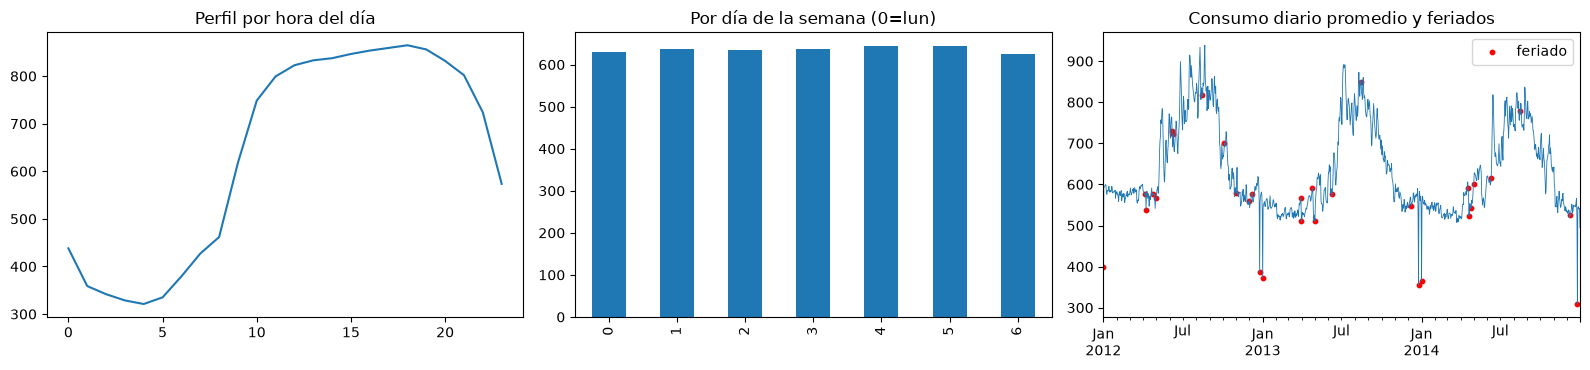

Consumo medio global: 635.93 | Navidad: 477.30 | Año Nuevo: 489.23


In [6]:
pt_holidays = holidays.country_holidays("PT", years=range(2012, 2015))
is_hol = pd.Series(panel.index.normalize().isin(pd.to_datetime(list(pt_holidays.keys()))), index=panel.index)
total = panel.mean(axis=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
total.groupby(total.index.hour).mean().plot(ax=ax[0], title="Perfil por hora del día")
total.groupby(total.index.dayofweek).mean().plot(kind="bar", ax=ax[1], title="Por día de la semana (0=lun)")
daily = total.resample("1D").mean()
daily.plot(ax=ax[2], lw=.6, title="Consumo diario promedio y feriados")
hd = daily[daily.index.isin(pd.to_datetime(list(pt_holidays.keys())))]
ax[2].scatter(hd.index, hd.values, c="r", s=10, label="feriado"); ax[2].legend()
plt.tight_layout(); plt.show()

christmas = total[(total.index.month == 12) & (total.index.day.isin([24, 25, 26]))].mean()
newyear = total[((total.index.month == 12) & (total.index.day == 31)) | ((total.index.month == 1) & (total.index.day <= 2))].mean()
print(f"Consumo medio global: {total.mean():.2f} | Navidad: {christmas:.2f} | Año Nuevo: {newyear:.2f}")

### 2.5 Escalas entre clientes y normalización

In [7]:
mean_by_client = panel.loc[:TRAIN_END].mean()
print(mean_by_client.describe()[["min", "50%", "max"]])
print("Razón max/min:", mean_by_client.max() / max(mean_by_client.min(), 1e-9))

min        2.368338
50%      147.286342
max    48817.757447
dtype: float64
Razón max/min: 20612.665246373203


**Decisión (a completar con los resultados):** las escalas difieren en varios órdenes de magnitud, por lo que
una normalización global dominaría la pérdida con los clientes grandes. Se usa **z-score por serie con
estadísticos calculados solo en entrenamiento** (media y desviación de 2012-01-01 a 2014-06-30), y para modelos
con RevIN, normalización por ventana. Las métricas se calculan siempre en kWh originales.

In [8]:
mu = panel.loc[:TRAIN_END].mean()
sd = panel.loc[:TRAIN_END].std().replace(0, 1.0)
panel_z = (panel - mu) / sd            # usado como entrada; se invierte para evaluar

### 2.6 Covariables de calendario conocidas a futuro
`hora`, `día de la semana` y `mes` se codifican con **seno/coseno** (preservan la ciclicidad, sin explosión de
dimensiones del one-hot) y `feriado` como binaria. Todas se conocen a futuro, por lo que pueden entrar al decoder.

In [9]:
def calendar_features(idx):
    f = pd.DataFrame(index=idx)
    for name, val, per in [("hour", idx.hour, 24), ("dow", idx.dayofweek, 7), ("month", idx.month - 1, 12)]:
        f[f"{name}_sin"] = np.sin(2 * np.pi * val / per)
        f[f"{name}_cos"] = np.cos(2 * np.pi * val / per)
    f["holiday"] = idx.normalize().isin(pd.to_datetime(list(pt_holidays.keys()))).astype(float)
    return f.astype("float32")

cal = calendar_features(panel.index)
cal.head(3)

,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,holiday
2012-01-01 00:00:00,0.000000,1.000000,-0.781832,0.62349,0.0,1.0,1.0
2012-01-01 01:00:00,0.258819,0.965926,-0.781832,0.62349,0.0,1.0,1.0
2012-01-01 02:00:00,0.500000,0.866025,-0.781832,0.62349,0.0,1.0,1.0


## 3. Dataset de ventanas deslizantes
Cada muestra: `X` = (L, features) con el consumo normalizado + calendario, `y` = (H,) siguiente 24 h.
El origen `t` es la primera hora a pronosticar; la entrada usa solo `[t-L, t-1]`.
Se agregan también las covariables de calendario de `[t, t+H-1]` (`x_fut`), conocidas a futuro.

In [10]:
class WindowDataset(Dataset):
    """Ventanas (X: L x F, y: H) sobre todas las series. Origenes t en [start, end] (inclusive) con paso `stride`.
    El target de cada ventana cae en [t, t+H-1]; se asigna a un split segun su ORIGEN t, y el target
    nunca excede el limite superior del split."""
    def __init__(self, values, cal, index, start, end, L=168, H=24, stride=1):
        self.v = torch.tensor(values.values, dtype=torch.float32)       # (T, N)
        self.c = torch.tensor(cal.values, dtype=torch.float32)          # (T, C)
        self.L, self.H = L, H
        i0 = max(index.get_indexer([pd.Timestamp(start)])[0], L)
        i1 = index.get_indexer([pd.Timestamp(end)])[0] - H + 1          # target dentro del split
        self.origins = np.arange(i0, i1 + 1, stride)
        self.N = self.v.shape[1]
    def __len__(self): return len(self.origins) * self.N
    def __getitem__(self, k):
        t, n = self.origins[k // self.N], k % self.N
        past = self.v[t - self.L:t, n:n + 1]                            # (L, 1)
        x = torch.cat([past, self.c[t - self.L:t]], dim=1)              # (L, 1+C)
        x_fut = self.c[t:t + self.H]                                    # (H, C) calendario futuro
        y = self.v[t:t + self.H, n]                                     # (H,)
        return x, x_fut, y, n

idx = panel.index
ds_train = WindowDataset(panel_z, cal, idx, START, TRAIN_END, L, H, STRIDE)
ds_val   = WindowDataset(panel_z, cal, idx, "2014-07-01 00:00", VAL_END, L, H, STRIDE)
ds_test  = WindowDataset(panel_z, cal, idx, "2014-10-01 00:00", END, L, H, STRIDE)
print(f"Ventanas (L={L}, H={H}, stride={STRIDE}) -> train: {len(ds_train):,} | val: {len(ds_val):,} | test: {len(ds_test):,}")
x, xf, y, n = ds_train[0]; print(x.shape, xf.shape, y.shape)

Ventanas (L=168, H=24, stride=1) -> train: 6,943,040 | val: 699,200 | test: 699,200
torch.Size([168, 8]) torch.Size([24, 7]) torch.Size([24])


> Nota: los primeros `L` pasos del bloque de validación y prueba pueden usar historia del bloque anterior como *entrada*
> (es información pasada legítima); lo que no puede cruzarse es el **target**. Aquí el `start` se limita para que
> el origen del primer target quede dentro del split, y el historial de entrada puede venir del split previo.

## 4. Auditoría de fugas
Cada entrada debe poder calcularse en el instante de emitir el pronóstico (00:00 con datos hasta 23:00).

In [11]:
# (1) Split aleatorio de ventanas -> se usa split CRONOLOGICO por origen/target
assert panel.index[ds_train.origins[-1] + H - 1] <= pd.Timestamp(TRAIN_END)
assert panel.index[ds_val.origins[0]] > pd.Timestamp(TRAIN_END) - pd.Timedelta(hours=H)  # sin solape de targets con train
assert panel.index[ds_val.origins[-1] + H - 1] <= pd.Timestamp(VAL_END)
assert panel.index[ds_test.origins[0]] > pd.Timestamp(VAL_END) - pd.Timedelta(hours=H)
print("(1) Splits cronologicos, targets sin solape entre train/val/test: OK")

# (2) Escalado con toda la serie -> mu y sd salen solo de TRAIN
assert np.allclose(mu.values, panel.loc[:TRAIN_END].mean().values)
mu_full = panel.mean()
print("(2) mu usa solo train; diferencia vs. media global (promedio relativo): "
      f"{((mu - mu_full).abs() / mu_full).mean():.3%}")

# (3) Early stopping con la prueba -> la seleccion usa solo val; test se evalua una vez por modelo
print("(3) Early stopping/seleccion de hiperparametros: solo con ds_val (ver secciones de entrenamiento)")

# (4) Covariables mal alineadas: el calendario se calcula del indice y x_fut se toma en [t, t+H-1]
k = 100
t = ds_train.origins[k // ds_train.N]
x, xf, y, n = ds_train[k]
assert torch.allclose(x[:, 0], torch.tensor(panel_z.values[t - L:t, n], dtype=torch.float32))   # pasado
assert torch.allclose(y, torch.tensor(panel_z.values[t:t + H, n], dtype=torch.float32))         # futuro
assert torch.allclose(xf, torch.tensor(cal.values[t:t + H]))      # calendario futuro (conocido)
assert panel_z.index[t - 1] < panel_z.index[t]                    # la entrada termina antes del origen
print("(4) Entrada = [t-L, t-1]; target = [t, t+H-1]; solo calendario (determinista) se usa a futuro: OK")

(1) Splits cronologicos, targets sin solape entre train/val/test: OK


(2) mu usa solo train; diferencia vs. media global (promedio relativo): 1.299%


(3) Early stopping/seleccion de hiperparametros: solo con ds_val (ver secciones de entrenamiento)
(4) Entrada = [t-L, t-1]; target = [t, t+H-1]; solo calendario (determinista) se usa a futuro: OK


## 5. Protocolo de validación y métricas
`backtest(model)` se implementa **una sola vez**: origen móvil diario en prueba (92 orígenes, a las 00:00 de cada día
del 2014-10-01 al 2014-12-31); cada modelo expone `predict(history_df, origin) -> array (n_clients, H)` en kWh.

In [12]:
TEST_ORIGINS = pd.date_range("2014-10-01 00:00", "2014-12-31 00:00", freq="1D")
assert len(TEST_ORIGINS) == 92

def backtest(predict_fn, panel_kwh=panel, origins=TEST_ORIGINS, H=H):
    """predict_fn(history: DataFrame hasta origin-1h, origin) -> ndarray (n_clientes, H) en kWh.
    Devuelve DataFrame largo (unique_id, ds, origin, h, y, y_hat)."""
    rows = []
    for o in origins:
        hist = panel_kwh.loc[:o - pd.Timedelta(hours=1)]            # solo datos hasta las 23:00
        pred = np.asarray(predict_fn(hist, o))                      # (N, H)
        ds = pd.date_range(o, periods=H, freq="1h")
        real = panel_kwh.loc[ds].values.T                           # (N, H)
        for i, c in enumerate(panel_kwh.columns):
            rows.append(pd.DataFrame({"unique_id": c, "ds": ds, "origin": o, "h": np.arange(1, H + 1),
                                      "y": real[i], "y_hat": pred[i]}))
    return pd.concat(rows, ignore_index=True)

def metrics(df, train_panel=None, m=24):
    e = df.y_hat - df.y
    out = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
           "WAPE": e.abs().sum() / df.y.abs().sum()}
    nz = df.y.abs() > 1e-6
    out["MAPE"] = (e[nz].abs() / df.y[nz].abs()).mean()             # explota con consumo ~ 0
    if train_panel is not None:                                      # MASE: escala = MAE naive estacional en train
        scale = train_panel.diff(m).abs().mean()                     # por cliente
        mae_c = e.abs().groupby(df.unique_id).mean()
        out["MASE"] = (mae_c / scale.reindex(mae_c.index)).mean()
    return pd.Series(out)

# Ejemplo con seasonal naive 24 h (verifica el pipeline)
def snaive24(hist, origin): return hist.iloc[-24:].values.T
bt = backtest(snaive24)
metrics(bt, panel.loc[:TRAIN_END])

MAE      49.425375
RMSE    391.807998
WAPE      0.084667
MAPE      0.149705
MASE      1.046026
dtype: float64

In [13]:
# Error por paso del horizonte, por hora del dia y semana 22-28 dic
def breakdown(bt):
    ae = (bt.y_hat - bt.y).abs()
    return (ae.groupby(bt.h).mean(), ae.groupby(bt.ds.dt.hour).mean(),
            bt[(bt.ds >= "2014-12-22") & (bt.ds < "2014-12-29")])
by_h, by_hour, xmas = breakdown(bt)
print("MAE semana 22-28 dic:", (xmas.y_hat - xmas.y).abs().mean())

MAE semana 22-28 dic: 100.39073142623594


## 6. Panel de modelado (100 clientes) y módulo `src/lab9.py`
Por restricciones de cómputo (GPU de 6 GB) todos los modelos usan **el mismo subconjunto de 100 clientes**, elegido con semilla fija (42)
entre los 320 completos (`src/prep_data.py`). El módulo `src/lab9.py` contiene las implementaciones propias (Dataset de ventanas en GPU,
`backtest`, métricas, MLP, DLinear, NLinear, LSTM, LSTM autorregresivo y seq2seq, y el ciclo de entrenamiento `fit`).
Las celdas siguientes lo importan y **muestran su código fuente**; el entrenamiento pesado se corrió con los scripts de `src/` y sus
resultados (`results/*.json`) se cargan aquí.

In [14]:
import sys, json, inspect
sys.path.insert(0, "../src" if os.path.basename(os.getcwd()) == "notebooks" else "src")
import lab9
from lab9 import *
RES_DIR = lab9.RES
df100 = load_panel(100); P = Panel(df100)
scale = mase_scale(df100.iloc[:P.pos_train_end])
print("clientes:", P.N, "| horas:", P.T)
for s in ("train", "val", "test"):
    print(f"ventanas {s} (L=168, H=24, stride 1): {len(P.origins(s, 168)) * P.N:,}")

clientes: 100 | horas: 26304
ventanas train (L=168, H=24, stride 1): 2,169,700
ventanas val (L=168, H=24, stride 1): 218,500
ventanas test (L=168, H=24, stride 1): 218,500


## 7. Implementaciones propias (PyTorch)
Todas reciben `past (B, L, 1+C)` (valor normalizado + calendario) y `fut (B, H, C)` (calendario futuro) y devuelven `(B, H)`.
`Net` añade la normalización (z-score por serie o por ventana, tipo RevIN sin parámetros afines) y la reversión.

In [15]:
for obj in (lab9.MLP, lab9.DLinear, lab9.NLinear):
    print(inspect.getsource(obj))

class MLP(Core):
    def __init__(self, L, C, H=H, hidden=256, layers=2, dropout=0.1):
        super().__init__()
        dims, mods = L + H * C, []
        for _ in range(layers):
            mods += [nn.Linear(dims, hidden), nn.ReLU(), nn.Dropout(dropout)]; dims = hidden
        self.net = nn.Sequential(*mods, nn.Linear(dims, H))

    def forward(self, past, fut): return self.net(torch.cat([past[..., 0], fut.flatten(1)], dim=1))

class DLinear(Core):
    """Descomposicion tendencia (media movil, kernel 25) + resto; una capa lineal L->H por componente."""
    def __init__(self, L, C, H=H, kernel=25):
        super().__init__()
        self.k = kernel
        self.pool = nn.AvgPool1d(kernel, stride=1)
        self.lin_s, self.lin_t = nn.Linear(L, H), nn.Linear(L, H)

    def forward(self, past, fut):
        x = past[..., 0]
        pad = torch.cat([x[:, :1].repeat(1, (self.k - 1) // 2), x, x[:, -1:].repeat(1, (self.k - 1) // 2)], 1)
        trend = self.pool(pad.unsqueeze(1)).squeeze(

In [16]:
for obj in (lab9.LSTMMulti, lab9.LSTMAuto, lab9.Seq2Seq, lab9.Net):
    print(inspect.getsource(obj))

class LSTMMulti(Core):
    """Multi-salida: LSTM sobre la ventana, ultimo estado oculto (+calendario futuro) -> capa densa con H salidas."""
    def __init__(self, L, C, H=H, hidden=64, layers=1, dropout=0.1, cell="lstm"):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(1 + C, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0.)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden + H * C, H))

    def forward(self, past, fut):
        out, _ = self.rnn(past)
        return self.head(torch.cat([out[:, -1], fut.flatten(1)], 1))

class LSTMAuto(Core):
    """Autorregresivo: paso de entrada [z_s, cal_{s+1}] -> z_{s+1}. Entrena con teacher forcing sobre toda la
    secuencia (L+H); en inferencia realimenta su propia prediccion durante H pasos."""
    def __init__(self, L, C, H=H, hidden=64, layers=1, dropout=0.1, cell="lstm"):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else 

### 7.1 Ciclo de entrenamiento y backtest
Pérdida L1, AdamW, cosine annealing, recorte de gradiente, early stopping **solo con validación**. La prueba se evalúa una vez por modelo.

In [17]:
print(inspect.getsource(lab9.fit))
print(inspect.getsource(lab9.make_predict_fn))

def fit(panel, cfg, train_end_pos=None, verbose=True, fixed_epochs=None):
    """Entrena un modelo global sobre todas las series. Early stopping y seleccion solo con validacion.
    Si fixed_epochs, entrena exactamente ese numero de epochs sin validacion (reentrenamiento mensual)."""
    cfg = {**DEFAULT, **cfg}
    seed_all(cfg["seed"])
    L, C = cfg["L"], panel.C.shape[1]
    kw = {k: cfg[k] for k in ("hidden", "layers", "dropout") if k in cfg}
    m = cfg["model"]
    if m in ("dlinear", "nlinear"): kw = {}
    if m == "mlp": kw = dict(hidden=cfg["hidden"], layers=cfg["layers"], dropout=cfg["dropout"])
    net = Net(CORES[m](L, C, **kw), cfg["norm"]).to(panel.dev)
    ds_tr = WindowDataset(panel, panel.origins("train", L, months=cfg["months"], train_end_pos=train_end_pos), L)
    ds_va = WindowDataset(panel, panel.origins("val", L), L, stride=4)
    opt = torch.optim.AdamW(net.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    crit = nn.L1Loss() if cfg["loss"] == "l1" else nn.

### 7.2 Ejemplo ejecutable: DLinear (3 epochs) y backtest en prueba

In [18]:
cfg = dict(model="dlinear", L=168, epochs=3, spe=300, lr=3e-3)
net, info = fit(P, cfg, verbose=False)
bt100 = lab9.backtest(make_predict_fn(net, P, 168), df100)
print("MASE val:", round(info["best_val_mase"], 4), "| prueba:", lab9.metrics(bt100, scale).round(3).to_dict(), f"| {info['train_time']:.0f} s")

MASE val: 0.8484 | prueba: {'MAE': 33.887, 'RMSE': 104.07, 'WAPE': 0.071, 'MAPE': 0.106, 'MASE': 0.897} | 2 s


## 8. Baselines, LightGBM y modelos de librería
Scripts: `src/run_baselines.py` (StatsForecast: Naive, SeasonalNaive 24/168, MSTL; LightGBM global recursivo con rezagos 1–24, 168 y calendario),
`src/run_nf.py` + `src/run_nf_test.py` (NeuralForecast: NHITS, TCN, PatchTST, iTransformer) y `src/run_chronos.py` (Chronos-Bolt zero-shot).
**Hallazgo:** al pasar el calendario como `futr_exog_list` NHITS y TCN divergían (MASE 1.66 y 29.5 en validación); sin exógenas convergen
(0.833 y 0.890), por lo que los modelos de NeuralForecast se reportan sin covariables. **DeepAR no se completó** (error de memoria en
validación y tiempo de entrenamiento excesivo en una GPU de 6 GB).

In [19]:
runs = load_json("runs.json"); runs_nf = load_json("runs_nf.json"); runs_lgb = load_json("runs_lgb.json")
for k, v in runs_nf.items(): print(f"{k:22s} val_MASE={v['val_mase']:.4f} params={v['params_total']:,} t={v['train_time']:.0f}s")
for k, v in runs_lgb.items(): print(f"{k:22s} val_MASE={v['val_mase']:.4f}")

nhits_L168             val_MASE=1.6628 params=1,503,507 t=1392s
patchtst_L168          val_MASE=0.8885 params=466,843 t=115s
tcn_L168               val_MASE=29.4899 params=76,761 t=101s
nhits_L168_v2          val_MASE=2.8064 params=604,563 t=1354s
tcn_L168_v2            val_MASE=32.6898 params=76,761 t=77s
tcn_L168_noex          val_MASE=0.8897 params=74,521 t=94s
nhits_L168_noex        val_MASE=0.8329 params=815,379 t=383s
itransformer_L168      val_MASE=0.8048 params=289,944 t=71s
patchtst_m3            val_MASE=0.8667 params=466,843 t=82s
patchtst_m12           val_MASE=0.8812 params=466,843 t=95s
lgb_base               val_MASE=0.8823
lgb_leaves15           val_MASE=0.8997
lgb_lr0.1_leaves127    val_MASE=0.8676
lgb_m3                 val_MASE=0.9123
lgb_m12                val_MASE=0.8873
lgb_m30                val_MASE=0.8823


## 9. Iteraciones de hiperparámetros (5.2)
Selección **solo con validación** (2014-07-01 a 2014-09-30). Se registran configuración (L, meses de historia, normalización, hidden, capas,
dropout, lr, batch), pérdidas por epoch, MAE y MASE de validación, parámetros, tiempos y memoria pico de GPU (`runs.json`).

In [20]:
rows = []
for rid, r in runs.items():
    c, hs = r["cfg"], r["history"]
    rows.append(dict(id=rid, L=c["L"], meses=c["months"] or 30, norm=c["norm"], hidden=c["hidden"], capas=c["layers"], dropout=c["dropout"], lr=c["lr"],
                     bs=c["bs"], epochs=len(hs), train_loss=hs[-1]["train_loss"], val_loss=hs[-1]["val_loss"], val_mae=min(h["val_mae"] for h in hs),
                     val_mase=r["best_val_mase"], params=r["params_total"], s_por_epoch=np.mean([h["epoch_time"] for h in hs]),
                     t_total_s=r["train_time"], gpu_mb=r["gpu_peak_mb"]))
it = pd.DataFrame(rows).sort_values("val_mase"); it.round(4)

,id,L,meses,norm,hidden,capas,dropout,lr,bs,epochs,train_loss,val_loss,val_mae,val_mase,params,s_por_epoch,t_total_s,gpu_mb
15,mlp_L168_win,168,30,window,256,2,0.1,0.001,256,20,0.2604,0.1998,30.2953,0.8000,158232,1.5376,31.5155,117.7739
14,mlp_L336,336,30,z,256,2,0.1,0.001,256,20,0.2155,0.2001,30.2235,0.8026,201240,1.4388,29.5445,190.0410
12,mlp_L168,168,30,z,256,2,0.1,0.001,256,20,0.2191,0.2038,30.8208,0.8161,158232,1.4779,30.1701,116.2700
10,nlinear_L336,336,30,z,64,1,0.1,0.001,256,20,0.2086,0.2063,30.7815,0.8172,8088,1.0368,21.4900,180.9702
5,dlinear_lr3e-3,336,30,z,64,1,0.1,0.003,256,20,0.2091,0.2069,30.9955,0.8208,16176,1.2863,26.5831,181.2192
6,dlinear_m3,168,3,z,64,1,0.1,0.001,256,20,0.2104,0.2121,31.6695,0.8261,8112,1.2687,25.9907,113.3535
13,mlp_L168_h512_l3,168,30,z,512,3,0.2,0.001,256,20,0.2241,0.2053,31.3851,0.8283,710168,1.7011,34.9963,127.9731
11,nlinear_L168_win,168,30,window,64,1,0.1,0.001,256,20,0.2640,0.2128,31.7959,0.8345,4056,1.1439,23.6546,113.3608
3,dlinear_L168_win,168,30,window,64,1,0.1,0.001,256,20,0.2640,0.2128,31.7950,0.8346,8112,1.3804,28.4802,113.5039
2,dlinear_L336,336,30,z,64,1,0.1,0.001,256,7,0.2119,0.2120,31.6630,0.8347,16176,1.2677,9.1964,181.1587


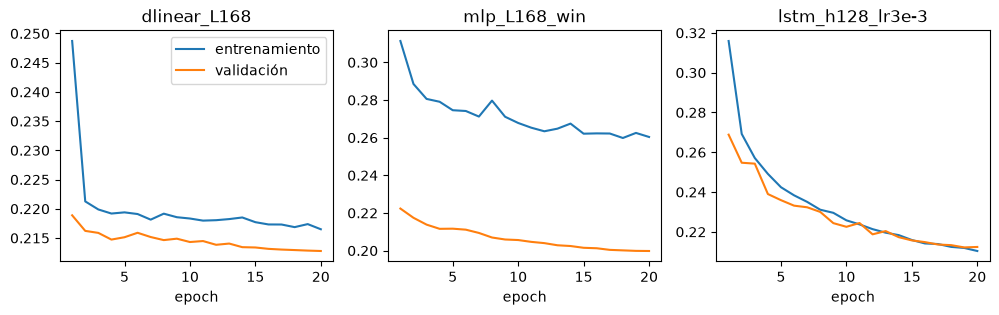

In [21]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for a, rid in zip(axs, ["dlinear_L168", "mlp_L168_win", "lstm_h128_lr3e-3"]):
    hs = runs[rid]["history"]; e = [x["epoch"] for x in hs]
    a.plot(e, [x["train_loss"] for x in hs], label="entrenamiento"); a.plot(e, [x["val_loss"] for x in hs], label="validación")
    a.set_title(rid); a.set_xlabel("epoch")
axs[0].legend(); plt.show()

**¿Menor pérdida de entrenamiento implica mejor MASE de validación?** No necesariamente: ver la comparación de las curvas y de la columna
`val_mase` contra `train_loss` en la tabla de iteraciones (las LSTM alcanzan pérdidas de entrenamiento comparables a las de DLinear/MLP,
pero un MASE de validación peor).

## 10. Estrategias multi-paso del LSTM (5.1) y local vs global (5.3)

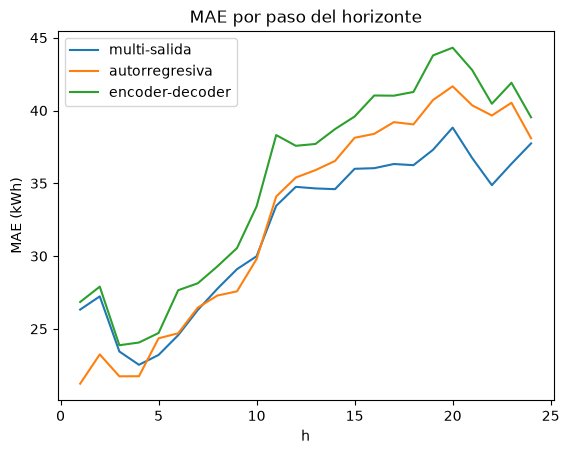

In [22]:
fin = {}
for f in ("final_baselines", "final_own", "final_nf", "final_chronos"): fin.update(load_json(f + ".json"))
h = np.arange(1, 25)
for k, lab in [("LSTM (multi-salida)", "multi-salida"), ("LSTM (autorregresivo)", "autorregresiva"), ("Seq2seq LSTM", "encoder-decoder")]:
    plt.plot(h, fin[k]["mae_by_h"], label=lab)
plt.xlabel("h"); plt.ylabel("MAE (kWh)"); plt.legend(); plt.title("MAE por paso del horizonte"); plt.show()

In [23]:
lg = load_json("local_global.json")
print(f"10 clientes {lg['clients']}")
print(f"MASE global={lg['MASE_global']:.4f} | local={lg['MASE_local']:.4f} (entrenamiento local total {lg['train_time_local_total']:.0f} s en 10 modelos)")
pd.DataFrame(lg["per_client"]).round(4)

10 clientes ['MT_014', 'MT_051', 'MT_101', 'MT_168', 'MT_200', 'MT_206', 'MT_235', 'MT_280', 'MT_310', 'MT_327']
MASE global=0.8519 | local=0.8081 (entrenamiento local total 177 s en 10 modelos)


,unique_id,mean_kwh,MASE_global,MASE_local
0,MT_014,44.8959,0.5527,0.5055
1,MT_051,54.6220,0.7267,0.7215
2,MT_101,706.0167,0.7630,0.6324
3,MT_168,134.6466,0.8775,0.9219
4,MT_200,824.5530,0.8311,0.7684
5,MT_206,201.0180,0.8894,0.7835
6,MT_235,774.0022,1.1061,1.0781
7,MT_280,284.9827,0.9408,0.9478
8,MT_310,591.8879,0.7913,0.7686
9,MT_327,543.8668,1.0401,0.9538


## 11. Reentrenamiento mensual y semillas
`src/run_retrain.py`: al inicio de cada mes de prueba se reentrena con toda la historia disponible (ventana expandible) y se pronostica ese mes.
`src/run_seeds.py`: mejor modelo propio (MLP) y mejor modelo de librería (iTransformer) con 3 semillas.

In [24]:
rt = load_json("retrain.json")
print(pd.DataFrame({k: {"MASE fijo": v["MASE_fixed"], "MASE mensual": v["MASE"], "MAE fijo": v["MAE_fixed"], "MAE mensual": v["MAE"]} for k, v in rt.items()}).T.round(4))
print(json.dumps(load_json("seeds.json"), indent=1))

              MASE fijo  MASE mensual  MAE fijo  MAE mensual
MLP              0.8255        0.8268   30.5222      30.6789
iTransformer     0.8061        0.8037   29.8696      29.7006
MSTL             0.9115        0.9133   35.1632      35.1827
{
 "MLP": {
  "MASE_by_seed": {
   "42": 0.8255313400429357,
   "43": 0.8209425471223842,
   "44": 0.8223949141766275
  },
  "mean": 0.8229562671139825,
  "std": 0.002345334295390245
 },
 "iTransformer": {
  "MASE_by_seed": {
   "1": 0.8060980642394893,
   "2": 0.8305157947217364,
   "3": 0.799840250888005
  },
  "mean": 0.8121513699497437,
  "std": 0.01620892130556941
 }
}


## 12. Comparación final sobre prueba (ordenada por MASE) y archivo de pronósticos

In [25]:
cmp = pd.read_csv(os.path.join(RES_DIR, "comparison.csv")); cmp.round(4)

,Modelo,Familia,L,Estrategia,Covariables,Params,Params_entren,T_entren_s,T_infer_s,Hardware,MAE,RMSE,WAPE,MAPE,MASE,MASE_22_28dic,Pinball,Cobertura_P10_P90
0,Chronos-Bolt,Fundacional,512,directa (zero-shot),no,47718016,0,0.0000,6.6892,GPU,28.0917,89.3048,0.0586,0.0844,0.7596,1.3560,9.3707,0.8037
1,iTransformer,Transformer/NF,168,multi-salida,no,289944,289944,70.9098,5.4097,GPU,29.8696,90.5569,0.0623,0.0941,0.8061,1.3899,NaN,NaN
2,NHITS,Transformer/NF,168,multi-salida,no,815379,815379,383.0410,6.2315,GPU,29.9529,94.5456,0.0625,0.0935,0.8112,1.4462,NaN,NaN
3,MLP,MLP y lineales,168,multi-salida,si,158232,158232,31.5155,0.0933,GPU,30.5222,92.6878,0.0637,0.0932,0.8255,1.4683,NaN,NaN
4,TCN,Transformer/NF,168,multi-salida,no,74521,74521,94.0350,7.4821,GPU,31.3494,98.5136,0.0654,0.0952,0.8489,1.5978,NaN,NaN
5,NLinear,MLP y lineales,336,multi-salida,no,8088,8088,21.4900,0.0711,GPU,31.9567,99.8727,0.0667,0.1001,0.8528,1.7972,NaN,NaN
6,DLinear,MLP y lineales,336,multi-salida,no,16176,16176,26.5831,0.1312,GPU,32.0840,99.9448,0.0669,0.1001,0.8547,1.7986,NaN,NaN
7,LSTM (autorregresivo),Recurrentes,168,autorregresiva,si,70785,70785,425.2132,1.1969,GPU,32.7443,101.9385,0.0683,0.0953,0.8570,1.4576,NaN,NaN
8,LSTM (multi-salida),Recurrentes,168,multi-salida,si,77784,77784,289.1115,0.3387,GPU,31.8469,96.8364,0.0664,0.0969,0.8578,1.3814,NaN,NaN
9,LightGBM,Arboles,168,recursiva,si,1497,1497,98.9606,5.3478,CPU,32.5158,105.6054,0.0678,0.0937,0.8667,1.5944,NaN,NaN


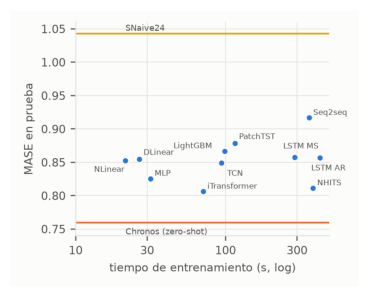

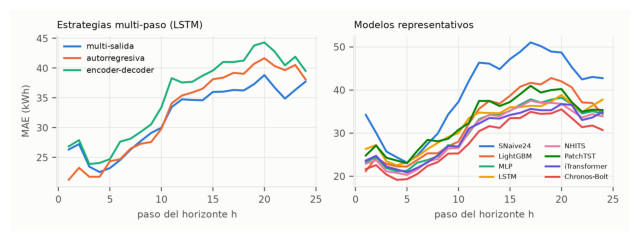

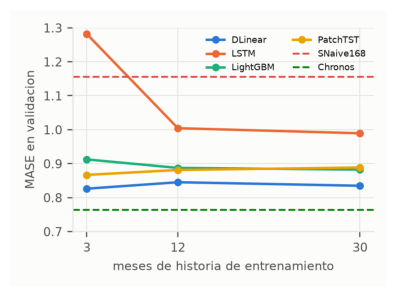

(3532800, 4) 16 modelos; ['unique_id', 'ds', 'modelo', 'y_hat']


,unique_id,ds,modelo,y_hat
0,MT_014,2014-10-01 00:00:00,Naive,41.002
1,MT_019,2014-10-01 00:00:00,Naive,9.045
2,MT_020,2014-10-01 00:00:00,Naive,52.203
3,MT_022,2014-10-01 00:00:00,Naive,20.859
4,MT_025,2014-10-01 00:00:00,Naive,209.112


In [26]:
import matplotlib.image as mpimg
FIGDIR = os.path.join(lab9.ROOT, "report", "figs")
for f in ("pareto.png", "mae_horizon.png", "months.png"):
    if os.path.exists(os.path.join(FIGDIR, f)):
        plt.figure(figsize=(8, 3.6)); plt.imshow(mpimg.imread(os.path.join(FIGDIR, f))); plt.axis("off"); plt.show()
pred = pd.read_csv(os.path.join(RES_DIR, "predictions_test.csv.gz"))
print(pred.shape, pred.modelo.nunique(), "modelos;", pred.columns.tolist()); pred.head()